<a href="https://colab.research.google.com/github/pedrons/BBB/blob/main/diffusers/stable_diffusion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Stable Diffusion** 🎨
*...using `🧨diffusers`*

Stable Diffusion is a text-to-image latent diffusion model created by the researchers and engineers from [CompVis](https://github.com/CompVis), [Stability AI](https://stability.ai/) and [LAION](https://laion.ai/). It's trained on 512x512 images from a subset of the [LAION-5B](https://laion.ai/blog/laion-5b/) database. This model uses a frozen CLIP ViT-L/14 text encoder to condition the model on text prompts. With its 860M UNet and 123M text encoder, the model is relatively lightweight and can run on many consumer GPUs.
See the [model card](https://huggingface.co/CompVis/stable-diffusion) for more information.

This Colab notebook shows how to use Stable Diffusion with the 🤗 Hugging Face [🧨 Diffusers library](https://github.com/huggingface/diffusers).

Let's get started!

## 1. How to use `StableDiffusionPipeline`

Before diving into the theoretical aspects of how Stable Diffusion functions,
let's try it out a bit 🤗.

In this section, we show how you can run text to image inference in just a few lines of code!

### Setup

First, please make sure you are using a GPU runtime to run this notebook, so inference is much faster. If the following command fails, use the `Runtime` menu above and select `Change runtime type`.

In [1]:
import torch

In [2]:
if torch.cuda.is_available():
    # Shows the nVidia GPUs, if this system has any
    !nvidia-smi

Fri May 15 04:44:08 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8             10W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

Next, you should install `diffusers` as well `scipy`, `ftfy` and `transformers`. `accelerate` is used to achieve much faster loading.

In [3]:
!pip install diffusers==0.11.1
!pip install transformers scipy ftfy accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 524.9/524.9 kB 13.7 MB/s eta 0:00:00
  Attempting uninstall: diffusers
    Found existing installation: diffusers 0.37.1
    Uninstalling diffusers-0.37.1:
      Successfully uninstalled diffusers-0.37.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 3.0 MB/s eta 0:00:00


### Stable Diffusion Pipeline

`StableDiffusionPipeline` is an end-to-end inference pipeline that you can use to generate images from text with just a few lines of code.

First, we load the pre-trained weights of all components of the model. In this notebook we use Stable Diffusion version 1.4 ([CompVis/stable-diffusion-v1-4](https://huggingface.co/CompVis/stable-diffusion-v1-4)), but there are other variants that you may want to try:
* [runwayml/stable-diffusion-v1-5](https://huggingface.co/runwayml/stable-diffusion-v1-5)
* [stabilityai/stable-diffusion-2-1-base](https://huggingface.co/stabilityai/stable-diffusion-2-1-base)
* [stabilityai/stable-diffusion-2-1](https://huggingface.co/stabilityai/stable-diffusion-2-1). This version can produce images with a resolution of 768x768, while the others work at 512x512.

In addition to the model id [CompVis/stable-diffusion-v1-4](https://huggingface.co/CompVis/stable-diffusion-v1-4), we're also passing a specific `revision` and `torch_dtype` to the `from_pretrained` method.

We want to ensure that every free Google Colab can run Stable Diffusion, hence we're loading the weights from the half-precision branch [`fp16`](https://huggingface.co/CompVis/stable-diffusion-v1-4/tree/fp16) and also tell `diffusers` to expect the weights in float16 precision by passing `torch_dtype=torch.float16`.

If you want to ensure the highest possible precision, please make sure to remove `torch_dtype=torch.float16` at the cost of a higher memory usage.

In [4]:
# This is added to get around some issues of Torch not loading models correctly (test on Mac OS X and Kubuntu Linux)
!pip install --upgrade huggingface-hub==0.26.2 transformers==4.46.1 tokenizers==0.20.1 diffusers==0.31.0

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.1/44.1 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 447.5/447.5 kB 15.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 65.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 48.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 39.3 MB/s eta 0:00:00
  Attempting uninstall: huggingface-hub
    Found existing installation: huggingface_hub 1.11.0
    Uninstalling huggingface_hub-1.11.0:
      Successfully uninstalled huggingface_hub-1.11.0
  Attempting uninstall: tokenizers
    Found existing installation: tokenizers 0.22.2
    Uninstalling tokenizers-0.22.2:
      Successfully uninstalled tokenizers-0.22.2
  Attempting uninstall: diffusers
    Found existing installation: diffusers 0.11.1
    Uninstalling diffusers-0.11.1:
      Successfully uninstalled diffusers-0.11.1
  Attempting uninstall: transformers
    Found existing installation: transfo

In [5]:
from diffusers import StableDiffusionPipeline

pipe = StableDiffusionPipeline.from_pretrained("CompVis/stable-diffusion-v1-4", torch_dtype=torch.float16)

The cache for model files in Transformers v4.22.0 has been updated. Migrating your old cache. This is a one-time only operation. You can interrupt this and resume the migration later on by calling `transformers.utils.move_cache()`.


0it [00:00, ?it/s]

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 16 files:   0%|          | 0/16 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

... (11 outputs left out)

config.json:   0%|          | 0.00/551 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/3.44G [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Next, let's move the pipeline to GPU to have faster inference.

In [6]:
if torch.cuda.is_available():
    device=torch.device("cuda")
elif torch.backends.mps.is_available():
    device=torch.device("mps")

pipe = pipe.to(device)

And we are ready to generate images:

  0%|          | 0/50 [00:00<?, ?it/s]

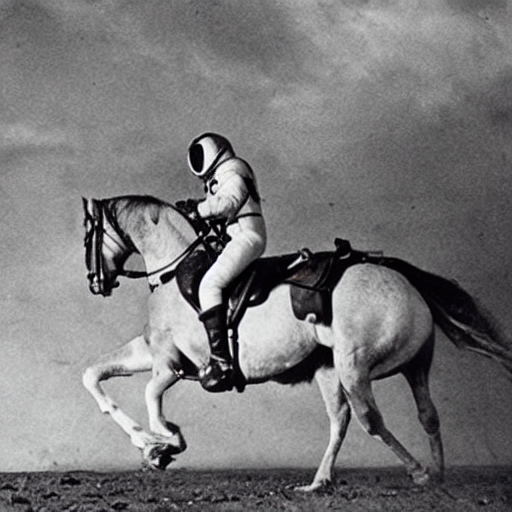

In [7]:
prompt = "a photograph of an astronaut riding a horse"
image = pipe(prompt).images[0]  # image here is in [PIL format](https://pillow.readthedocs.io/en/stable/)

# Now to display an image you can either save it such as:
image.save(f"astronaut_rides_horse.png")

# or if you're in a google colab you can directly display it with
image

Running the above cell multiple times will give you a different image every time. If you want deterministic output you can pass a random seed to the pipeline. Every time you use the same seed you'll have the same image result.

  0%|          | 0/50 [00:00<?, ?it/s]

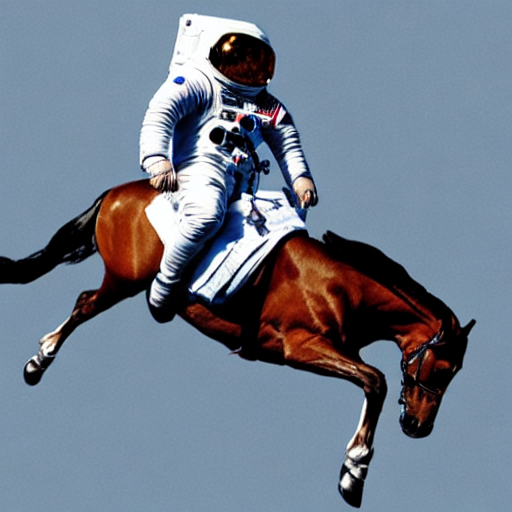

In [8]:
generator = torch.Generator(device).manual_seed(1024)

image = pipe(prompt, generator=generator).images[0]

image

You can change the number of inference steps using the `num_inference_steps` argument. In general, results are better the more steps you use. Stable Diffusion, being one of the latest models, works great with a relatively small number of steps, so we recommend to use the default of `50`. If you want faster results you can use a smaller number.

The following cell uses the same seed as before, but with fewer steps. Note how some details, such as the horse's head or the helmet, are less defin realistic and less defined than in the previous image:

  0%|          | 0/15 [00:00<?, ?it/s]

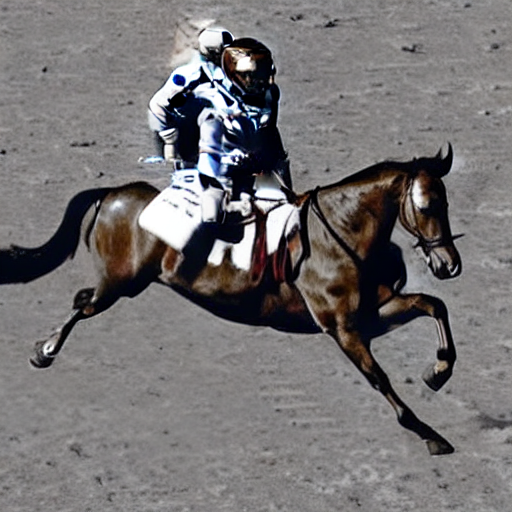

In [9]:
generator = torch.Generator(device).manual_seed(1024)

image = pipe(prompt, num_inference_steps=15, generator=generator).images[0]

image

The other parameter in the pipeline call is `guidance_scale`. It is a way to increase the adherence to the conditional signal which in this case is text as well as overall sample quality. In simple terms classifier free guidance forces the generation to better match with the prompt. Numbers like `7` or `8.5` give good results, if you use a very large number the images might look good, but will be less diverse.

You can learn about the technical details of this parameter in [the last section](https://colab.research.google.com/drive/1ALXuCM5iNnJDNW5vqBm5lCtUQtZJHN2f?authuser=1#scrollTo=UZp-ynZLrS-S) of this notebook.

To generate multiple images for the same prompt, we simply use a list with the same prompt repeated several times. We'll send the list to the pipeline instead of the string we used before.



Let's first write a helper function to display a grid of images. Just run the following cell to create the `image_grid` function, or disclose the code if you are interested in how it's done.

In [10]:
from PIL import Image

def image_grid(imgs, rows, cols):
    assert len(imgs) == rows*cols

    w, h = imgs[0].size
    grid = Image.new('RGB', size=(cols*w, rows*h))
    grid_w, grid_h = grid.size

    for i, img in enumerate(imgs):
        grid.paste(img, box=(i%cols*w, i//cols*h))
    return grid

Now, we can generate a grid image once having run the pipeline with a list of 3 prompts.

  0%|          | 0/50 [00:00<?, ?it/s]

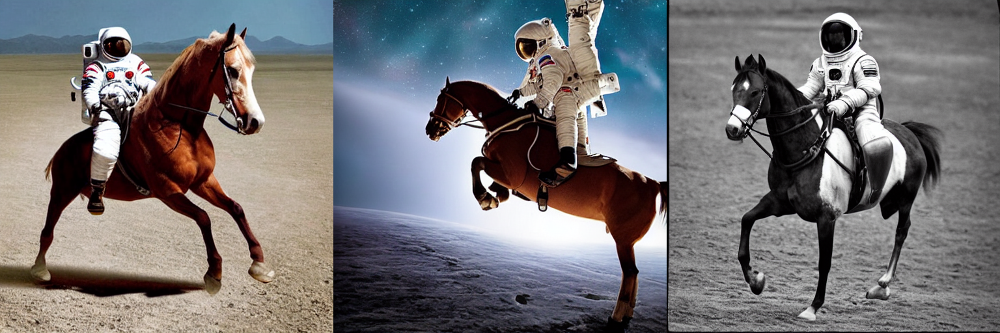

In [11]:
num_images = 3
prompt = ["a photograph of an astronaut riding a horse"] * num_images

images = pipe(prompt).images

grid = image_grid(images, rows=1, cols=3)
grid

And here's how to generate a grid of `n × m` images.

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

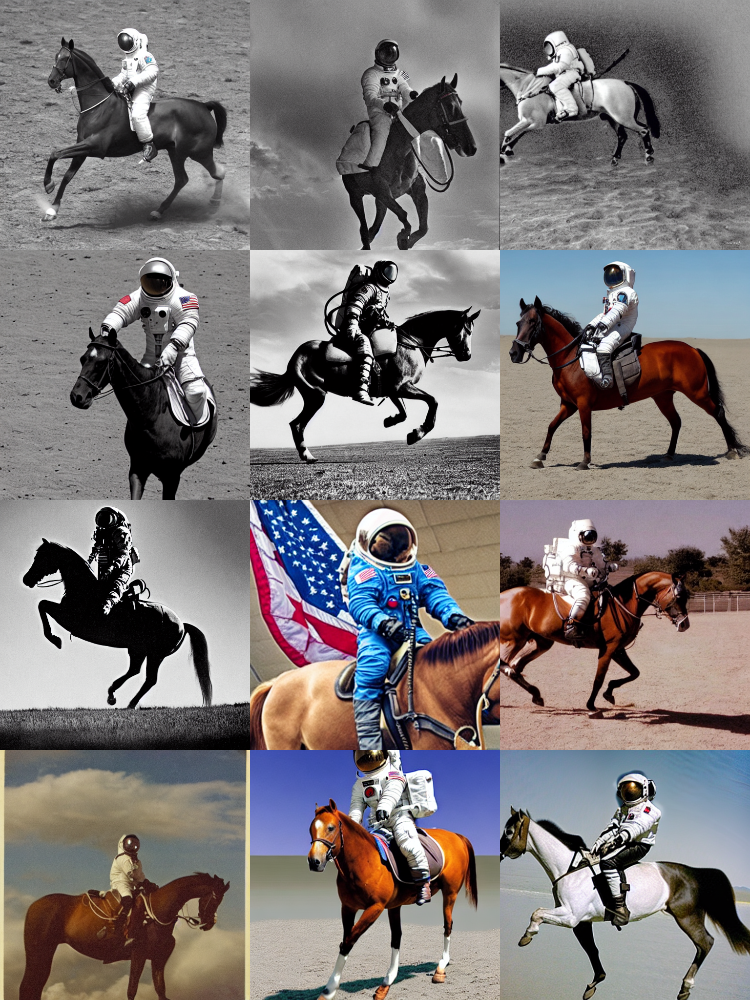

In [12]:
num_cols = 3
num_rows = 4

prompt = ["a photograph of an astronaut riding a horse"] * num_cols

all_images = []
for i in range(num_rows):
  images = pipe(prompt).images
  all_images.extend(images)

grid = image_grid(all_images, rows=num_rows, cols=num_cols)
grid

### Generate non-square images

Stable Diffusion produces images of `512 × 512` pixels by default. But it's very easy to override the default using the `height` and `width` arguments, so you can create rectangular images in portrait or landscape ratios.

These are some recommendations to choose good image sizes:
- Make sure `height` and `width` are both multiples of `8`.
- Going below 512 might result in lower quality images.
- Going over 512 in both directions will repeat image areas (global coherence is lost).
- The best way to create non-square images is to use `512` in one dimension, and a value larger than that in the other one.

  0%|          | 0/50 [00:00<?, ?it/s]

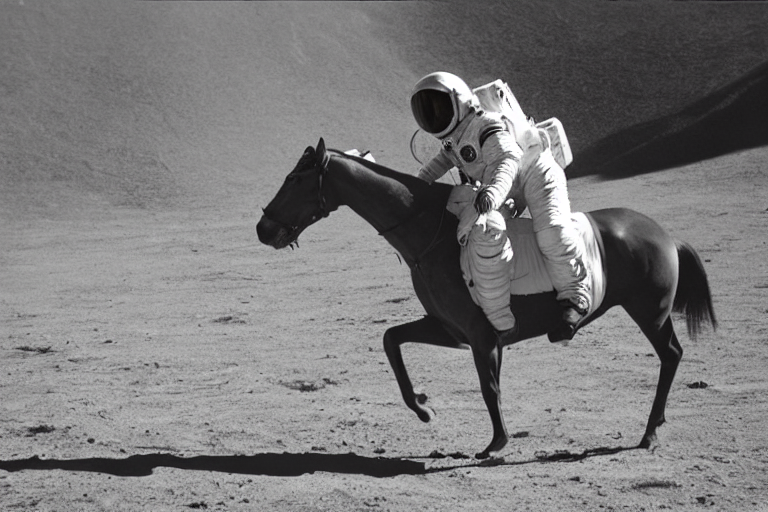

In [13]:
prompt = "a photograph of an astronaut riding a horse"

image = pipe(prompt, height=512, width=768).images[0]
image

## 2. What is Stable Diffusion

Now, let's go into the theoretical part of Stable Diffusion 👩‍🎓.

Stable Diffusion is based on a particular type of diffusion model called **Latent Diffusion**, proposed in [High-Resolution Image Synthesis with Latent Diffusion Models](https://arxiv.org/abs/2112.10752).



General diffusion models are machine learning systems that are trained to *denoise* random gaussian noise step by step, to get to a sample of interest, such as an *image*. For a more detailed overview of how they work, check [this colab](https://colab.research.google.com/github/huggingface/notebooks/blob/main/diffusers/diffusers_intro.ipynb).

Diffusion models have shown to achieve state-of-the-art results for generating image data. But one downside of diffusion models is that the reverse denoising process is slow. In addition, these models consume a lot of memory because they operate in pixel space, which becomes unreasonably expensive when generating high-resolution images. Therefore, it is challenging to train these models and also use them for inference.



<br>

Latent diffusion can reduce the memory and compute complexity by applying the diffusion process over a lower dimensional _latent_ space, instead of using the actual pixel space. This is the key difference between standard diffusion and latent diffusion models: **in latent diffusion the model is trained to generate latent (compressed) representations of the images.**

There are three main components in latent diffusion.

1. An autoencoder (VAE).
2. A [U-Net](https://colab.research.google.com/github/huggingface/notebooks/blob/main/diffusers/diffusers_intro.ipynb#scrollTo=wW8o1Wp0zRkq).
3. A text-encoder, *e.g.* [CLIP's Text Encoder](https://huggingface.co/docs/transformers/model_doc/clip#transformers.CLIPTextModel).

**1. The autoencoder (VAE)**

The VAE model has two parts, an encoder and a decoder. The encoder is used to convert the image into a low dimensional latent representation, which will serve as the input to the *U-Net* model.
The decoder, conversely, transforms the latent representation back into an image.

 During latent diffusion _training_, the encoder is used to get the latent representations (_latents_) of the images for the forward diffusion process, which applies more and more noise at each step. During _inference_, the denoised latents generated by the reverse diffusion process are converted back into images using the VAE decoder. As we will see during inference we **only need the VAE decoder**.

**2. The U-Net**

The U-Net has an encoder part and a decoder part both comprised of ResNet blocks.
The encoder compresses an image representation into a lower resolution image representation and the decoder decodes the lower resolution image representation back to the original higher resolution image representation that is supposedly less noisy.
More specifically, the U-Net output predicts the noise residual which can be used to compute the predicted denoised image representation.

To prevent the U-Net from losing important information while downsampling, short-cut connections are usually added between the downsampling ResNets of the encoder to the upsampling ResNets of the decoder.
Additionally, the stable diffusion U-Net is able to condition its output on text-embeddings via cross-attention layers. The cross-attention layers are added to both the encoder and decoder part of the U-Net usually between ResNet blocks.

**3. The Text-encoder**

The text-encoder is responsible for transforming the input prompt, *e.g.* "An astronout riding a horse" into an embedding space that can be understood by the U-Net. It is usually a simple *transformer-based* encoder that maps a sequence of input tokens to a sequence of latent text-embeddings.

Inspired by [Imagen](https://imagen.research.google/), Stable Diffusion does **not** train the text-encoder during training and simply uses an CLIP's already trained text encoder, [CLIPTextModel](https://huggingface.co/docs/transformers/model_doc/clip#transformers.CLIPTextModel).

**Why is latent diffusion fast and efficient?**

Since the U-Net of latent diffusion models operates on a low dimensional space, it greatly reduces the memory and compute requirements compared to pixel-space diffusion models. For example, the autoencoder used in Stable Diffusion has a reduction factor of 8. This means that an image of shape `(3, 512, 512)` becomes `(3, 64, 64)` in latent space, which requires `8 × 8 = 64` times less memory.

This is why it's possible to generate `512 × 512` images so quickly, even on 16GB Colab GPUs!

**Stable Diffusion during inference**

Putting it all together, let's now take a closer look at how the model works in inference by illustrating the logical flow.


<p align="left">
<img src="https://raw.githubusercontent.com/patrickvonplaten/scientific_images/master/stable_diffusion.png" alt="sd-pipeline" width="500"/>
</p>

The stable diffusion model takes both a latent seed and a text prompt as an input. The latent seed is then used to generate random latent image representations of size $64 \times 64$ where as the text prompt is transformed to text embeddings of size $77 \times 768$ via CLIP's text encoder.

Next the U-Net iteratively *denoises* the random latent image representations while being conditioned on the text embeddings. The output of the U-Net, being the noise residual, is used to compute a denoised latent image representation via a scheduler algorithm. Many different scheduler algorithms can be used for this computation, each having its pros and cons. For Stable Diffusion, we recommend using one of:

- [PNDM scheduler](https://github.com/huggingface/diffusers/blob/main/src/diffusers/schedulers/scheduling_pndm.py) (used by default).
- [K-LMS scheduler](https://github.com/huggingface/diffusers/blob/main/src/diffusers/schedulers/scheduling_lms_discrete.py).
- [Heun Discrete scheduler](https://github.com/huggingface/diffusers/blob/main/src/diffusers/schedulers/scheduling_heun_discrete.py).
- [DPM Solver Multistep scheduler](https://github.com/huggingface/diffusers/blob/main/src/diffusers/schedulers/scheduling_dpmsolver_multistep.py). This scheduler is able to achieve great quality in less steps. You can try with 25 instead of the default 50!

Theory on how the scheduler algorithm function is out of scope for this notebook, but in short one should remember that they compute the predicted denoised image representation from the previous noise representation and the predicted noise residual.
For more information, we recommend looking into [Elucidating the Design Space of Diffusion-Based Generative Models](https://arxiv.org/abs/2206.00364)

The *denoising* process is repeated *ca.* 50 times to step-by-step retrieve better latent image representations.
Once complete, the latent image representation is decoded by the decoder part of the variational auto encoder.



After this brief introduction to Latent and Stable Diffusion, let's see how to make advanced use of 🤗 Hugging Face Diffusers!

## 3. How to write your own inference pipeline with `diffusers`

Finally, we show how you can create custom diffusion pipelines with `diffusers`.
This is often very useful to dig a bit deeper into certain functionalities of the system and to potentially switch out certain components.

In this section, we will demonstrate how to use Stable Diffusion with a different scheduler, namely [Katherine Crowson's](https://github.com/crowsonkb) K-LMS scheduler that was added in [this PR](https://github.com/huggingface/diffusers/pull/185#pullrequestreview-1074247365).

Let's go through the `StableDiffusionPipeline` step by step to see how we could have written it ourselves.

We will start by loading the individual models involved.

The [pre-trained model](https://huggingface.co/CompVis/stable-diffusion-v1-3-diffusers/tree/main) includes all the components required to setup a complete diffusion pipeline. They are stored in the following folders:
- `text_encoder`: Stable Diffusion uses CLIP, but other diffusion models may use other encoders such as `BERT`.
- `tokenizer`. It must match the one used by the `text_encoder` model.
- `scheduler`: The scheduling algorithm used to progressively add noise to the image during training.
- `unet`: The model used to generate the latent representation of the input.
- `vae`: Autoencoder module that we'll use to decode latent representations into real images.

We can load the components by referring to the folder they were saved, using the `subfolder` argument to `from_pretrained`.

In [14]:
from transformers import CLIPTextModel, CLIPTokenizer
from diffusers import AutoencoderKL, UNet2DConditionModel, PNDMScheduler

# 1. Load the autoencoder model which will be used to decode the latents into image space.
vae = AutoencoderKL.from_pretrained("CompVis/stable-diffusion-v1-4", subfolder="vae")

# 2. Load the tokenizer and text encoder to tokenize and encode the text.
tokenizer = CLIPTokenizer.from_pretrained("openai/clip-vit-large-patch14")
text_encoder = CLIPTextModel.from_pretrained("openai/clip-vit-large-patch14")

# 3. The UNet model for generating the latents.
unet = UNet2DConditionModel.from_pretrained("CompVis/stable-diffusion-v1-4", subfolder="unet")

tokenizer_config.json:   0%|          | 0.00/905 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.71G [00:00<?, ?B/s]

Now instead of loading the pre-defined scheduler, we'll use the K-LMS scheduler instead.

In [15]:
from diffusers import LMSDiscreteScheduler

scheduler = LMSDiscreteScheduler.from_pretrained("CompVis/stable-diffusion-v1-4", subfolder="scheduler")

Next we move the models to the GPU.

In [16]:
vae = vae.to(device)
text_encoder = text_encoder.to(device)
unet = unet.to(device)

We now define the parameters we'll use to generate images.

Note that `guidance_scale` is defined analog to the guidance weight `w` of equation (2) in the [Imagen paper](https://arxiv.org/pdf/2205.11487.pdf). `guidance_scale == 1` corresponds to doing no classifier-free guidance. Here we set it to 7.5 as also done previously.

In contrast to the previous examples, we set `num_inference_steps` to 100 to get an even more defined image.

In [17]:
prompt = ["a photograph of an astronaut riding a horse"]

height = 512                        # default height of Stable Diffusion
width = 512                         # default width of Stable Diffusion

num_inference_steps = 100            # Number of denoising steps

guidance_scale = 7.5                # Scale for classifier-free guidance

generator = torch.manual_seed(32)   # Seed generator to create the inital latent noise

batch_size = 1

First, we get the text_embeddings for the prompt. These embeddings will be used to condition the UNet model.

In [18]:
text_input = tokenizer(prompt, padding="max_length", max_length=tokenizer.model_max_length, truncation=True, return_tensors="pt")

with torch.no_grad():
  text_embeddings = text_encoder(text_input.input_ids.to(device))[0]

We'll also get the unconditional text embeddings for classifier-free guidance, which are just the embeddings for the padding token (empty text). They need to have the same shape as the conditional `text_embeddings` (`batch_size` and `seq_length`)

In [19]:
max_length = text_input.input_ids.shape[-1]
uncond_input = tokenizer(
    [""] * batch_size, padding="max_length", max_length=max_length, return_tensors="pt"
)
with torch.no_grad():
  uncond_embeddings = text_encoder(uncond_input.input_ids.to(device))[0]

For classifier-free guidance, we need to do two forward passes. One with the conditioned input (`text_embeddings`), and another with the unconditional embeddings (`uncond_embeddings`). In practice, we can concatenate both into a single batch to avoid doing two forward passes.

In [20]:
text_embeddings = torch.cat([uncond_embeddings, text_embeddings])

Generate the intial random noise.

In [21]:
latents = torch.randn(
  (batch_size, unet.in_channels, height // 8, width // 8),
  generator=generator,
)
latents = latents.to(device)

/tmp/ipykernel_678/2156330459.py:2: FutureWarning: Accessing config attribute `in_channels` directly via 'UNet2DConditionModel' object attribute is deprecated. Please access 'in_channels' over 'UNet2DConditionModel's config object instead, e.g. 'unet.config.in_channels'.
  (batch_size, unet.in_channels, height // 8, width // 8),


In [22]:
latents.shape

torch.Size([1, 4, 64, 64])

Cool $64 \times 64$ is expected. The model will transform this latent representation (pure noise) into a `512 × 512` image later on.

Next, we initialize the scheduler with our chosen `num_inference_steps`.
This will compute the `sigmas` and exact time step values to be used during the denoising process.

In [23]:
scheduler.set_timesteps(num_inference_steps)

The K-LMS scheduler needs to multiply the `latents` by its `sigma` values. Let's do this here

In [24]:
latents = latents * scheduler.init_noise_sigma

We are ready to write the denoising loop.

In [25]:
from tqdm.auto import tqdm
from torch import autocast

for t in tqdm(scheduler.timesteps):
  # expand the latents if we are doing classifier-free guidance to avoid doing two forward passes.
  latent_model_input = torch.cat([latents] * 2)

  latent_model_input = scheduler.scale_model_input(latent_model_input, t)

  # predict the noise residual
  with torch.no_grad():
    noise_pred = unet(latent_model_input, t, encoder_hidden_states=text_embeddings).sample

  # perform guidance
  noise_pred_uncond, noise_pred_text = noise_pred.chunk(2)
  noise_pred = noise_pred_uncond + guidance_scale * (noise_pred_text - noise_pred_uncond)

  # compute the previous noisy sample x_t -> x_t-1
  latents = scheduler.step(noise_pred, t, latents).prev_sample

  0%|          | 0/100 [00:00<?, ?it/s]

We now use the `vae` to decode the generated `latents` back into the image.

In [26]:
# scale and decode the image latents with vae
latents = 1 / 0.18215 * latents

with torch.no_grad():
  image = vae.decode(latents).sample

And finally, let's convert the image to PIL so we can display or save it.

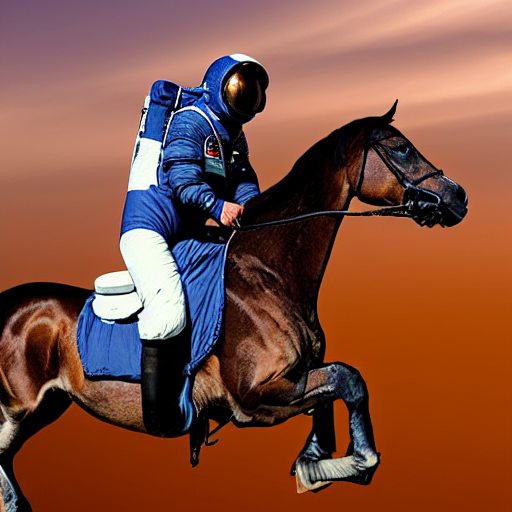

In [27]:
image = (image / 2 + 0.5).clamp(0, 1)
image = image.detach().cpu().permute(0, 2, 3, 1).numpy()
images = (image * 255).round().astype("uint8")
pil_images = [Image.fromarray(image) for image in images]
pil_images[0]

Now you have all the pieces to build your own pipelines or use diffusers components as you like 🔥.

## 4. Create a Web Interface with Gradio

Let's create a simple web interface using `gradio` to make it easier to input prompts and generate images.

In [50]:
import gradio as gr
from diffusers import StableDiffusionPipeline
import torch

print("Carregando o modelo 'Realistic Vision V5.1', focado em alto realismo e detalhes...")
# Trocamos o modelo antigo (v1.4) por um modelo especializado em fotografia e rostos perfeitos
pipeline = StableDiffusionPipeline.from_pretrained("SG161222/Realistic_Vision_V5.1_noVAE", torch_dtype=torch.float16, safety_checker=None)

# Movemos para a placa de vídeo
pipeline = pipeline.to(device)
print("Modelo carregado com sucesso!")

def generate_image(prompt, num_inference_steps=30, guidance_scale=7.5, seed=-1):
    if seed == -1:
        generator = None
    else:
        generator = torch.Generator(device).manual_seed(seed)

    # Realistic Vision precisa de prompts descritivos (ex: RAW photo, 8k uhd, dslr, soft lighting, high quality)
    image = pipeline(
        prompt,
        num_inference_steps=num_inference_steps,
        guidance_scale=guidance_scale,
        generator=generator
    ).images[0]
    return image

Carregando o modelo 'Realistic Vision V5.1', focado em alto realismo e detalhes...


model_index.json:   0%|          | 0.00/609 [00:00<?, ?B/s]

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/737 [00:00<?, ?B/s]

scheduler_config.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

... (6 outputs left out)

diffusion_pytorch_model.safetensors:   0%|          | 0.00/3.44G [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Modelo carregado com sucesso!


In [51]:
iface = gr.Interface(
    fn=generate_image,
    inputs=[
        gr.Textbox(label="Prompt", placeholder="Enter your prompt here..."),
        gr.Slider(minimum=10, maximum=100, value=50, step=1, label="Number of Inference Steps"),
        gr.Slider(minimum=1.0, maximum=20.0, value=7.5, step=0.5, label="Guidance Scale"),
        gr.Number(label="Seed (enter -1 for random)", value=-1, step=1)
    ],
    outputs=gr.Image(label="Generated Image"),
    title="Stable Diffusion Image Generator",
    description="Generate images from text prompts using Stable Diffusion!"
)

iface.launch(debug=True, share=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://0ecb84cd8fc53d0119.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Token indices sequence length is longer than the specified maximum sequence length for this model (226 > 77). Running this sequence through the model will result in indexing errors
The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['high, legs spread wide, looking back over her shoulder with intense pleasure and lust in her eyes, mouth slightly open moaning. a large, muscular german shepherd dog is mounting her from behind, his front paws gripping her waist tightly, his thick red cock fully inserted deep inside her pussy, visible penetration with wet glistening details, the dog thrusting actively, balls slapping against her, intense bestial mating scene. detailed sweat on her skin, juices dripping down her thighs, realistic animal fur texture, muscular dog body, erotic and explicit bestiality, raw passionate expression, warm cinematic bedroom lighting with soft shadows, highly detailed skin pores and textures, photorealistic, 8 k, ul

  0%|          | 0/79 [00:00<?, ?it/s]

The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['bestiality scene, highly detailed, realistic lighting, cinematic, 8 k, photorealistic, sharp focus, erotic atmosphere, warm bedroom lighting "']


  0%|          | 0/64 [00:00<?, ?it/s]

The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['bestiality scene, highly detailed, realistic lighting, cinematic, 8 k, photorealistic, sharp focus, erotic atmosphere, warm bedroom lighting "']


... (16 outputs left out)

  0%|          | 0/84 [00:00<?, ?it/s]

  0%|          | 0/84 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/diffusers/configuration_utils.py:140: FutureWarning: Accessing config attribute `__iter__` directly via 'StableDiffusionPipeline' object attribute is deprecated. Please access '__iter__' over 'StableDiffusionPipeline's config object instead, e.g. 'scheduler.config.__iter__'.
  deprecate("direct config name access", "1.0.0", deprecation_message, standard_warn=False)
/usr/local/lib/python3.12/dist-packages/diffusers/configuration_utils.py:140: FutureWarning: Accessing config attribute `__iter__` directly via 'LMSDiscreteScheduler' object attribute is deprecated. Please access '__iter__' over 'LMSDiscreteScheduler's config object instead, e.g. 'scheduler.config.__iter__'.
  deprecate("direct config name access", "1.0.0", deprecation_message, standard_warn=False)
/usr/local/lib/python3.12/dist-packages/debugpy/_vendored/pydevd/_pydevd_bundle/pydevd_safe_repr.py:128: FutureWarning: Accessing config attribute `__iter__` directly via 'UNet2DConditionMod

Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://0ecb84cd8fc53d0119.gradio.live


In [ ]:
# Install xformers for potential memory optimization and speed improvements
!pip install xformers

### Loading a LoRA to Enhance Image Generation

To improve specific aspects like faces or body generation, you can load a LoRA. Many community-contributed LoRAs are available on the [Hugging Face Hub](https://huggingface.co/models?pipeline_tag=text-to-image&sort=downloads&search=lora).

Here's an example of how to load a hypothetical LoRA. You would replace `"path/to/your/lora"` with the actual model ID or local path of the LoRA you want to use. Please note that not all LoRAs are compatible with all `diffusers` pipelines or versions.

After loading, the LoRA weights will be applied to your `pipeline` object. When you run `generate_image`, the model will incorporate these new learned features.

In [48]:
import os

# Define the LoRA details
lora_name = "add_detail.safetensors"
lora_local_path = os.path.join("/content/", lora_name)

print("--------------------------------------------------")
print(f"To proceed, please ensure '{lora_name}' is uploaded to the /content/ directory.")
print(f"You can download it from: https://huggingface.co/cagliostro-project/stablediffusion-lora-add-detail/blob/main/{lora_name}")
print("Then, in Colab, open the 'Files' tab (folder icon on the left sidebar), and upload the file directly to /content/.")
print("After uploading, please re-run this cell.")
print("--------------------------------------------------")

# Check if the LoRA file exists locally
if os.path.exists(lora_local_path):
    try:
        print(f"Loading LoRA from {lora_local_path}...")
        pipeline.load_lora_weights(lora_file_path=lora_local_path, adapter_name="face_details_lora")
        print("LoRA for face enhancement loaded successfully!")
        print("You might pass `cross_attention_kwargs={'scale': 0.7}` to the pipeline call to adjust its strength. For this LoRA, a scale around 0.5-0.7 is often recommended.")

    except Exception as e:
        print(f"Could not load LoRA. Error: {e}")
else:
    print(f"Skipping LoRA loading: '{lora_name}' not found at {lora_local_path}.")
    print("Please upload the file as instructed above and re-run this cell.")

print("LoRA loading instructions updated. Please modify this cell to load your desired face enhancement LoRA if you want a different one.")

--------------------------------------------------
To proceed, please ensure 'add_detail.safetensors' is uploaded to the /content/ directory.
You can download it from: https://huggingface.co/cagliostro-project/stablediffusion-lora-add-detail/blob/main/add_detail.safetensors
Then, in Colab, open the 'Files' tab (folder icon on the left sidebar), and upload the file directly to /content/.
After uploading, please re-run this cell.
--------------------------------------------------
Skipping LoRA loading: 'add_detail.safetensors' not found at /content/add_detail.safetensors.
Please upload the file as instructed above and re-run this cell.
LoRA loading instructions updated. Please modify this cell to load your desired face enhancement LoRA if you want a different one.


In [33]:
# Install OpenCV for image processing, including face detection
!pip install opencv-python

### Face Detection for ADetailer-like functionality

After generating an initial image, the next step towards an ADetailer-like workflow is to detect faces or other regions you want to enhance. We'll use OpenCV's Haar Cascade classifier for this. Note that Haar Cascades are quite basic; for more robust detection, you might consider more advanced models from `dlib` or `mediapipe`.

Here's how you can detect faces in an image:

*(You might need to download the Haar Cascade XML file if it's not already available.)*

Using the last generated image for face detection example:


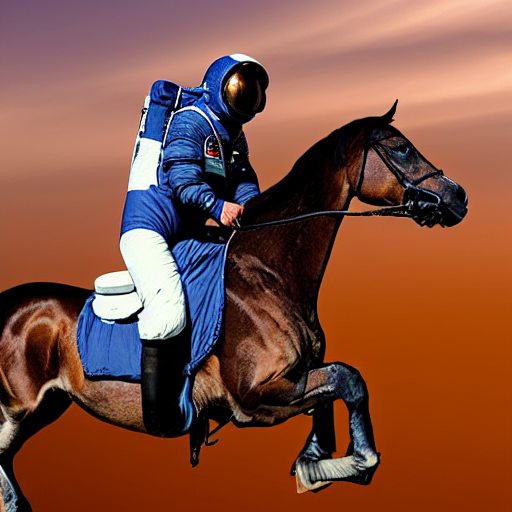

Detected faces: []
No faces detected in the example image.


In [35]:
import cv2
import numpy as np
from PIL import Image, ImageDraw # Added ImageDraw import

def detect_faces(image_pil):
    # Convert PIL Image to OpenCV format (numpy array)
    image_np = np.array(image_pil)
    image_gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY)

    # Download Haar Cascade classifier XML if not present
    try:
        face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
    except cv2.error:
        print("Haar Cascade XML not found. Please ensure opencv-python is installed correctly or download the file manually.")
        print("Trying to download from GitHub...")
        !wget -nc https://raw.githubusercontent.com/opencv/opencv/4.x/data/haarcascades/haarcascade_frontalface_default.xml -P /tmp/
        face_cascade = cv2.CascadeClassifier('/tmp/haarcascade_frontalface_default.xml')

    if face_cascade.empty():
        print("Error: Could not load face cascade classifier. Face detection will not work.")
        return []

    faces = face_cascade.detectMultiScale(
        image_gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(30, 30),
        flags=cv2.CASCADE_SCALE_IMAGE
    )
    # Corrected: Ensure 'faces' is always a list, even if detectMultiScale returns an empty tuple
    return list(faces) if isinstance(faces, tuple) else faces.tolist()

# Example usage with a previously generated image (assuming `pil_images[0]` or similar is available)
# Re-run a single image generation if you don't have one readily available
# prompt_for_detection = "a woman's face, highly detailed"
# generated_image = pipeline(prompt_for_detection).images[0]
# print("Generated image for face detection:")
# display(generated_image)

# Assuming `pil_images[0]` is the last generated image from the earlier part of the notebook
# If not, you'll need to generate an image first, for example:
# generated_image_for_adetailer = pipeline("a detailed portrait of a person").images[0]
# faces_detected = detect_faces(generated_image_for_adetailer)

if 'pil_images' in globals() and len(pil_images) > 0:
    example_image = pil_images[0]
    print("Using the last generated image for face detection example:")
    display(example_image)
    faces_detected = detect_faces(example_image)
    print(f"Detected faces: {faces_detected}")

    if faces_detected:
        # Draw rectangles around detected faces for visualization
        image_with_faces = example_image.copy()
        draw = ImageDraw.Draw(image_with_faces)
        for (x, y, w, h) in faces_detected:
            draw.rectangle([x, y, x + w, y + h], outline="red", width=3)
        print("Image with detected faces:")
        display(image_with_faces)

        # Next steps would involve cropping these regions, running an inpainting pipeline,
        # and compositing them back into the original image.
    else:
        print("No faces detected in the example image.")
else:
    print("No `pil_images` found. Please generate an image first to test face detection.")

### ADetailer-like Face Refinement Function

Now we'll create a function that takes an initial generated image, detects faces, and then uses the same `StableDiffusionPipeline` to re-generate and refine those detected face regions. This simulates ADetailer without needing a separate inpainting model.

This function will:
1.  Take an `original_image` and the `pipeline`.
2.  Detect faces using the `detect_faces` function.
3.  For each detected face, it will expand the bounding box slightly to capture more context.
4.  It will crop this expanded region, resize it to 512x512 (the native generation size), and then use the `pipeline` to generate a new image for that region with an enhanced prompt (e.g., 'detailed face').
5.  The newly generated face will be resized back to its original dimensions and pasted onto the `original_image`.

In [36]:
from PIL import ImageDraw

def expand_bbox(x, y, w, h, img_width, img_height, scale_factor=1.3):
    center_x, center_y = x + w / 2, y + h / 2
    new_w, new_h = w * scale_factor, h * scale_factor
    new_x, new_y = center_x - new_w / 2, center_y - new_h / 2

    # Ensure bounding box stays within image limits
    new_x = max(0, new_x)
    new_y = max(0, new_y)
    new_w = min(img_width - new_x, new_w)
    new_h = min(img_height - new_y, new_h)

    return int(new_x), int(new_y), int(new_w), int(new_h)

def adetailer_like_refine_faces(
    original_image,
    pipeline_t2i,
    base_prompt,
    num_inference_steps_refine=25, # Fewer steps for speed in refinement
    guidance_scale_refine=8.5,    # Higher guidance for detail in refinement
    face_prompt_suffix=", detailed face, beautiful eyes, hyperrealistic, high quality",
    scale_factor=1.2,
    seed=-1
):
    refined_image = original_image.copy()
    faces = detect_faces(original_image)

    if not faces:
        print("No faces detected for ADetailer-like refinement.")
        return original_image

    img_width, img_height = original_image.size
    print(f"Detected {len(faces)} face(s). Applying ADetailer-like refinement...")

    for (x, y, w, h) in faces:
        # Expand bounding box to get more context around the face
        ex, ey, ew, eh = expand_bbox(x, y, w, h, img_width, img_height, scale_factor)

        # Define a specific generator for this face if seed is provided
        generator_face = torch.Generator(device).manual_seed(seed) if seed != -1 else None

        # Create a prompt for refining the face
        face_gen_prompt = f"{base_prompt} {face_prompt_suffix}"

        # Generate a new image for the cropped face region (scaled to 512x512)
        # This will be a new image of a face, not an inpainting operation.
        # This is a simplification to avoid loading a full inpainting model.
        refined_face_512 = pipeline_t2i(
            face_gen_prompt,
            num_inference_steps=num_inference_steps_refine,
            guidance_scale=guidance_scale_refine,
            generator=generator_face,
            # For more controlled generation in a specific aspect ratio, you could pass
            # height=int(512 * (eh/ew)) and width=512, then resize appropriately.
            # But for simplicity, we'll generate 512x512 and resize.
        ).images[0]

        # Resize the refined face back to the expanded bounding box's original size
        refined_face_original_size = refined_face_512.resize((ew, eh))

        # Paste the refined face back into the image
        refined_image.paste(refined_face_original_size, (ex, ey))

    return refined_image

### Update Gradio Interface with ADetailer Option

Now, let's modify your Gradio interface to include a checkbox that allows you to enable or disable this ADetailer-like face refinement. We'll update the `generate_image` function to call our new `adetailer_like_refine_faces` function when the option is selected.

In [ ]:
# Modified generate_image function for Gradio to include advanced options
def generate_image_with_adetailer_option(prompt, negative_prompt="", num_inference_steps=30, guidance_scale=7.5, width=512, height=512, seed=-1, enable_adetailer=False):
    generator = torch.Generator(device).manual_seed(seed) if seed != -1 else None

    # Initial image generation
    initial_image = pipeline(
        prompt,
        negative_prompt=negative_prompt if negative_prompt else None,
        num_inference_steps=num_inference_steps,
        guidance_scale=guidance_scale,
        width=width,
        height=height,
        generator=generator
    ).images[0]

    if enable_adetailer:
        # Apply ADetailer-like refinement if enabled
        final_image = adetailer_like_refine_faces(
            initial_image,
            pipeline_t2i=pipeline,
            base_prompt=prompt,
            seed=seed # Pass the same seed for consistency in refinement if desired
        )
        return final_image
    else:
        return initial_image

# Update the Gradio interface definition with new inputs
iface_adetailer = gr.Interface(
    fn=generate_image_with_adetailer_option,
    inputs=[
        gr.Textbox(label="Prompt", placeholder="Descreva o que você quer ver..."),
        gr.Textbox(label="Negative Prompt (O que NÃO gerar)", placeholder="ugly, blurry, deformed...", value="ugly, blurry, deformed, poorly drawn face, bad anatomy, bad proportions, worst quality, low quality"),
        gr.Slider(minimum=10, maximum=100, value=30, step=1, label="Number of Inference Steps"),
        gr.Slider(minimum=1.0, maximum=20.0, value=7.5, step=0.5, label="Guidance Scale"),
        gr.Slider(minimum=256, maximum=1024, value=512, step=64, label="Width (Largura)"),
        gr.Slider(minimum=256, maximum=1024, value=512, step=64, label="Height (Altura)"),
        gr.Number(label="Seed (enter -1 for random)", value=-1, step=1),
        gr.Checkbox(label="Enable ADetailer-like Face Refinement", value=False)
    ],
    outputs=gr.Image(label="Generated Image"),
    title="Realistic Vision - Gerador Avançado",
    description="Gere imagens realistas controlando prompt negativo, resolução e detecção de rostos!"
)

# Launch the new Gradio interface
iface_adetailer.launch(debug=True, share=True)


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://e612fbba666cd79939.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


### 5. Image-to-Image (Modificando imagens existentes)

Aqui implementamos o pipeline `StableDiffusionImg2ImgPipeline`. Ele nos permite enviar uma imagem inicial e usar o texto para guiá-la. Note que reaproveitamos os componentes do modelo já carregado (`pipeline.components`) para não gastar memória extra.

In [56]:
import gradio as gr
from diffusers import StableDiffusionImg2ImgPipeline
import torch
from PIL import Image

print("Inicializando o pipeline Image-to-Image...")
# Reaproveitamos os componentes (unet, vae, text_encoder, etc.) do pipeline anterior
pipe_img2img = StableDiffusionImg2ImgPipeline(**pipeline.components)
pipe_img2img = pipe_img2img.to(device)
print("Pipeline Image-to-Image pronto!")

def generate_img2img(prompt, negative_prompt, init_image, strength, num_inference_steps, guidance_scale, seed):
    generator = torch.Generator(device).manual_seed(int(seed)) if seed != -1 else None

    # Se nenhuma imagem for enviada, usa o pipeline Text-to-Image (gerar do zero)
    if init_image is None:
        print("Nenhuma imagem base fornecida. Gerando do zero (Text-to-Image)...")
        result = pipeline(
            prompt=prompt,
            negative_prompt=negative_prompt if negative_prompt else None,
            num_inference_steps=num_inference_steps,
            guidance_scale=guidance_scale,
            generator=generator,
            width=512,
            height=512
        ).images[0]
        return result

    # Garante que a imagem está no formato correto (RGB)
    init_image = init_image.convert("RGB")

    # Redimensiona para um tamanho padrão do Stable Diffusion (múltiplos de 8)
    init_image = init_image.resize((512, 512))

    # Gera a nova imagem baseada na original
    result = pipe_img2img(
        prompt=prompt,
        negative_prompt=negative_prompt if negative_prompt else None,
        image=init_image,
        strength=strength, # Aumente este valor (ex: 0.85) para mudar mais a imagem!
        num_inference_steps=num_inference_steps,
        guidance_scale=guidance_scale,
        generator=generator
    ).images[0]

    return result

# Interface Gradio exclusiva para Image-to-Image
iface_img2img = gr.Interface(
    fn=generate_img2img,
    inputs=[
        gr.Textbox(label="Prompt", placeholder="Descreva a nova imagem ou as mudanças..."),
        gr.Textbox(label="Negative Prompt", value="ugly, blurry, deformed, poorly drawn face, bad anatomy, worst quality, low quality"),
        gr.Image(type="pil", label="Imagem Base (Upload opcional. Se vazio, gera do zero)"),
        gr.Slider(minimum=0.0, maximum=1.0, value=0.85, step=0.05, label="Strength (Importante: use > 0.8 para mudar mais a foto!)"),
        gr.Slider(minimum=10, maximum=100, value=30, step=1, label="Number of Inference Steps"),
        gr.Slider(minimum=1.0, maximum=20.0, value=7.5, step=0.5, label="Guidance Scale"),
        gr.Number(label="Seed (enter -1 for random)", value=-1, step=1)
    ],
    outputs=gr.Image(label="Imagem Modificada / Gerada"),
    title="Realistic Vision - Image-to-Image Híbrido",
    description="Faça upload de uma imagem e mude o 'Strength' para > 0.8 para aplicar grandes mudanças. Se não enviar imagem, ele gerará do zero!"
)

# Lança a interface
iface_img2img.launch(debug=True, share=True)


You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion_img2img.StableDiffusionImg2ImgPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


Inicializando o pipeline Image-to-Image...
Pipeline Image-to-Image pronto!
Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://bf6156e9cb34c78066.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Nenhuma imagem base fornecida. Gerando do zero (Text-to-Image)...


  0%|          | 0/30 [00:00<?, ?it/s]

Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://bf6156e9cb34c78066.gradio.live
